# HAM10000 + ISIC_Extra Binary Classification (Benign vs. Malignant) — DenseNet121 (Improved)

> **Baseline-dataset experiment.** This run uses the new merged dataset (`Data/datasets/HAM10000_ISICExtra_binary/` - HAM10000 + additional malignant/balancing samples from ISIC_Extra, produced by `01_preprocessing.ipynb`) as the **only** change from the original HAM10000-only baseline below. Architecture, hyperparameters, augmentation, loss, optimizer, schedule, and every other setting are identical to the original run, so the two can be compared directly to isolate the effect of the new dataset.

**This notebook combines and extends the two earlier experiments** (`03a_focal_loss` and
`03b_weighted_sampler`) into a single, upgraded training pipeline. It keeps everything that
worked, drops the parts that hurt precision too much, and adds a set of additional
techniques aimed specifically at improving the **benign vs. malignant separation** — the
actual bottleneck identified from the two earlier runs (both topped out around
ROC AUC ≈ 0.899).

## What changed vs. the two earlier notebooks

| Area | `03a` / `03b` | This notebook |
|---|---|---|
| Imbalance handling | Focal Loss **or** WeightedRandomSampler (separately) | **Class-Balanced Focal Loss** (Cui et al., 2019) + a *mild* (configurable) resampler — combined, not maxed out |
| Fine-tuning schedule | 2 phases (head → last dense block) | **3 phases** (head → last dense block → last **two** dense blocks), with **discriminative learning rates** |
| Regularization | Dropout only | Dropout + **BatchNorm in the head** + **MixUp** + **RandomErasing** + gradient clipping |
| Preprocessing | Resize + flips + rotation + color jitter | Same, plus optional **hair-removal preprocessing** (DullRazor-style) and RandomResizedCrop |
| Inference | Single forward pass | **Test-Time Augmentation** (original + h-flip + v-flip, averaged) |
| Decision threshold | Two fixed thresholds (0.5, 0.3) tried on the *test* set | Threshold **tuned on the validation set** (no test-set leakage) for two clinically meaningful operating points |
| Training speed | `num_workers=0`, FP32 | `num_workers>0` + **mixed precision (AMP)** |
| Metrics | Accuracy / P / R / F1 / AUC | Adds **specificity, NPV, balanced accuracy, MCC, Brier score**, and a calibration curve |

Each change is explained in its own markdown cell right before the code that implements it,
so you can see exactly why it's there and turn it off via `CONFIG` if you want to ablate it.

**New dependency:** hair removal uses OpenCV. Install it once if you don't have it:
`pip install opencv-python`. If it's not available, the notebook automatically disables
hair removal and keeps running.


## 1. Imports & Configuration

In [1]:
import copy
import json
import logging
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import WeightedRandomSampler
from torch.cuda.amp import autocast, GradScaler
from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, brier_score_loss,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression

try:
    import cv2
    CV2_AVAILABLE = True
except ImportError:
    CV2_AVAILABLE = False


In [2]:
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("ham10000_improved")

if not CV2_AVAILABLE:
    logger.warning("opencv-python not found — hair removal will be disabled automatically. "
                    "Install with `pip install opencv-python` to enable it.")


### Configuration

Everything tunable lives here. Flip any of the new flags off to ablate that change.

In [3]:
def find_project_root(start: Path, markers=("Data", "notebooks")) -> Path:
    '''Same root-finding approach as the earlier notebooks, so this works regardless of
    which machine runs it.'''
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if all((candidate / marker).exists() for marker in markers):
            return candidate
    raise FileNotFoundError(f"Could not find a project root containing {markers} above {start}.")


PROJECT_ROOT = find_project_root(Path.cwd())

OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "binary"
EXPERIMENT_NAME = "Binary_DenseNet121_Baseline_V2"

CONFIG = {
    # --- Paths -------------------------------------------------------------
    # Baseline-dataset experiment: this notebook consumes ONLY the outputs of
    # 01_preprocessing.ipynb (the merged HAM10000 + ISIC_Extra binary dataset). It never touches
    # Data/raw/, never re-splits, never re-runs dedup. Everything below this point in CONFIG -
    # architecture, hyperparameters, augmentation, training schedule - is unchanged from the
    # original HAM10000-only baseline, so the dataset is the only experimental variable.
    "metadata_dir": PROJECT_ROOT / "Data" / "datasets" / "HAM10000_ISICExtra_binary" / "metadata",
    "images_dir": PROJECT_ROOT / "Data" / "datasets" / "HAM10000_ISICExtra_binary" / "images",
    "output_dir": OUTPUT_ROOT / EXPERIMENT_NAME,
    "experiment_name": EXPERIMENT_NAME,

    "imbalance_method": "Class-Balanced Focal Loss + mild resampling + MixUp + TTA",

    # --- Image / DataLoader --------------------------------------------------
    "img_size": 224,
    "batch_size": 32,
    "num_workers": 0,          # if this hangs on Windows/Jupyter, set back to 0
    "hair_removal": True,      # auto-disabled below if opencv isn't installed

    # --- Imbalance handling --------------------------------------------------
    # soft_resample_power: 0.0 -> plain shuffle (no resampling at all)
    #                      0.5 -> "soft" resampling (sqrt of inverse frequency)
    #                      1.0 -> full inverse-frequency resampling, same as notebook 03b
    # We resample *mildly* here because full resampling (1.0) combined with a reweighted
    # loss over-corrects and tanks precision, as seen when comparing 03a vs 03b.
    "soft_resample_power": 0.5,
    "focal_gamma": 2.0,
    "cb_beta": 0.9999,         # class-balanced loss "beta" (Cui et al., 2019)

    # --- MixUp -----------------------------------------------------------
    "mixup_alpha": 0.2,
    "mixup_prob": 0.3,
    "mixup_phases": ["phase1_head_only", "phase2_finetune_block4"],  # disabled in phase 3 on purpose

    # --- Three-phase progressive fine-tuning, with discriminative LRs -------
    "phase1_epochs": 12,
    "phase1_head_lr": 1e-3,

    "phase2_epochs": 15,
    "phase2_head_lr": 5e-4,
    "phase2_backbone_lr": 1e-5,

    "phase3_epochs": 10,
    "phase3_head_lr": 1e-4,
    "phase3_backbone_lr": 5e-6,

    "weight_decay": 1e-4,
    "grad_clip_norm": 1.0,

    # --- Early stopping (monitored on validation AUC) ------------------------
    "early_stopping_patience": 6,

    # --- LR scheduler ------------------------------------------------------
    "scheduler_patience": 2,
    "scheduler_factor": 0.5,

    # --- Mixed precision -----------------------------------------------------
    "use_amp": True,

    # --- Test-time augmentation ----------------------------------------------
    "use_tta": True,

    # --- Threshold selection (tuned on validation set, applied to test set) --
    "high_sensitivity_target_recall": 0.90,

    # --- Misc --------------------------------------------------------------
    "random_seed": 42,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}

CONFIG["hair_removal"] = CONFIG["hair_removal"] and CV2_AVAILABLE

# Output directory structure - identical across all three V2 baselines (and the ensemble later).
CHECKPOINTS_DIR = CONFIG["output_dir"] / "checkpoints"
PREDICTIONS_DIR = CONFIG["output_dir"] / "predictions"
PLOTS_DIR = CONFIG["output_dir"] / "plots"
TRAINING_CURVES_DIR = PLOTS_DIR / "training_curves"
ROC_PR_DIR = PLOTS_DIR / "roc_pr_curves"
CONFUSION_MATRICES_DIR = PLOTS_DIR / "confusion_matrices"
CALIBRATION_DIR = PLOTS_DIR / "calibration"
PLOTS_ERROR_ANALYSIS_DIR = PLOTS_DIR / "error_analysis"
ERROR_ANALYSIS_DIR = CONFIG["output_dir"] / "error_analysis"  # CSVs + stats

for d in [CHECKPOINTS_DIR, PREDICTIONS_DIR, TRAINING_CURVES_DIR, ROC_PR_DIR,
          CONFUSION_MATRICES_DIR, CALIBRATION_DIR, PLOTS_ERROR_ANALYSIS_DIR, ERROR_ANALYSIS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

logger.info("Device: %s", CONFIG["device"])
logger.info("Imbalance method: %s", CONFIG["imbalance_method"])
logger.info("Hair removal enabled: %s", CONFIG["hair_removal"])
logger.info("Output dir: %s", CONFIG["output_dir"])


2026-07-22 12:07:43,168 | INFO | Device: cuda
2026-07-22 12:07:43,168 | INFO | Imbalance method: Class-Balanced Focal Loss + mild resampling + MixUp + TTA
2026-07-22 12:07:43,168 | INFO | Hair removal enabled: True
2026-07-22 12:07:43,168 | INFO | Output dir: D:\SkinCancer_Project\outputs\binary\Binary_DenseNet121_Baseline_V2


### Verify the dataset exists before doing anything else

In [4]:
REQUIRED_FILES = ["train.csv", "val.csv", "test.csv", "binary_label_encoder.pkl"]
REQUIRED_COLUMNS = {"image_id", "image_path", "dx", "binary_label"}
REQUIRED_IMAGE_SPLIT_DIRS = ["train", "val", "test"]


def verify_dataset(metadata_dir: Path, images_dir: Path) -> None:
    """Confirms the outputs of 01_preprocessing.ipynb (merged HAM10000 + ISIC_Extra binary
    dataset) are present and well-formed. This notebook treats those outputs as immutable - it
    only reads them, never regenerates or modifies preprocessing."""
    if not metadata_dir.exists():
        raise FileNotFoundError(
            f"Metadata directory not found: {metadata_dir}\n"
            "Expected the merged HAM10000 + ISIC_Extra binary splits produced by "
            "01_preprocessing.ipynb (Data/datasets/HAM10000_ISICExtra_binary/metadata/)."
        )
    missing = [f for f in REQUIRED_FILES if not (metadata_dir / f).exists()]
    if missing:
        raise FileNotFoundError(f"The following expected file(s) are missing from {metadata_dir}: {missing}")

    for filename in ["train.csv", "val.csv", "test.csv"]:
        cols = set(pd.read_csv(metadata_dir / filename, nrows=1).columns)
        missing_cols = REQUIRED_COLUMNS - cols
        if missing_cols:
            raise ValueError(f"{filename} is missing required column(s): {missing_cols}")

    missing_image_dirs = [d for d in REQUIRED_IMAGE_SPLIT_DIRS if not (images_dir / d).exists()]
    if missing_image_dirs:
        raise FileNotFoundError(
            f"The following processed image split folder(s) are missing from {images_dir}: {missing_image_dirs}"
        )

    logger.info("Dataset structure verified: %s | %s", metadata_dir, images_dir)


verify_dataset(CONFIG["metadata_dir"], CONFIG["images_dir"])


2026-07-22 12:07:43,179 | INFO | Dataset structure verified: D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary\metadata | D:\SkinCancer_Project\Data\datasets\HAM10000_ISICExtra_binary\images


## 2. Set Random Seeds

In [5]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # cudnn.benchmark=True picks the fastest conv algorithms for our fixed 224x224 input
    # size, at the cost of run-to-run bit-exact reproducibility. Set benchmark=False and
    # deterministic=True instead if you need strict reproducibility over raw speed.
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False


set_seed(CONFIG["random_seed"])
logger.info("Random seed set to %d", CONFIG["random_seed"])


2026-07-22 12:07:43,197 | INFO | Random seed set to 42


## 3. Data Loading

In [6]:
def load_binary_splits(metadata_dir: Path) -> dict:
    """Reads the immutable train/val/test splits written by 01_preprocessing.ipynb.
    No re-splitting, no re-merging, no dedup - the CSVs are the single source of truth."""
    splits = {}
    for name, filename in [("train", "train.csv"), ("valid", "val.csv"), ("test", "test.csv")]:
        df = pd.read_csv(metadata_dir / filename)
        splits[name] = df
        logger.info("Loaded %s: %d rows", filename, len(df))
    return splits


def resolve_processed_image_paths(df: pd.DataFrame, images_dir: Path, split_name: str) -> pd.DataFrame:
    """Inspects `image_path` first rather than blindly rebuilding it. Some preprocessing runs
    already write `image_path` pointing at the processed, copied image
    (Data/datasets/.../images/{split}/...) - in that case it is left untouched. Only when
    `image_path` still points somewhere else (e.g. the original Data/raw/... location it was
    read from before copying) is it rebuilt, by filename, against the correct split folder."""
    df = df.copy()
    split_dir = images_dir / split_name

    def _resolve(raw_path: str) -> str:
        current_path = Path(raw_path)
        if current_path.parent == split_dir:
            return str(current_path)  # already correct - do not modify
        return str(split_dir / current_path.name)  # still raw/stale - rebuild

    already_correct = (df["image_path"].apply(lambda p: Path(p).parent) == split_dir).sum()
    df["image_path"] = df["image_path"].apply(_resolve)
    logger.info(
        "%s: image_path already pointed at processed images for %d/%d row(s); rebuilt the rest",
        split_name, int(already_correct), len(df),
    )
    return df


splits = load_binary_splits(CONFIG["metadata_dir"])
train_df, valid_df, test_df = splits["train"], splits["valid"], splits["test"]

train_df = resolve_processed_image_paths(train_df, CONFIG["images_dir"], "train")
valid_df = resolve_processed_image_paths(valid_df, CONFIG["images_dir"], "val")
test_df = resolve_processed_image_paths(test_df, CONFIG["images_dir"], "test")

logger.info(
    "Sample sizes -> train: %d, valid: %d, test: %d", len(train_df), len(valid_df), len(test_df)
)


2026-07-22 12:07:43,214 | INFO | Loaded train.csv: 8587 rows
2026-07-22 12:07:43,214 | INFO | Loaded val.csv: 2147 rows
2026-07-22 12:07:43,230 | INFO | Loaded test.csv: 2147 rows
2026-07-22 12:07:43,313 | INFO | train: image_path already pointed at processed images for 0/8587 row(s); rebuilt the rest
2026-07-22 12:07:43,344 | INFO | val: image_path already pointed at processed images for 0/2147 row(s); rebuilt the rest
2026-07-22 12:07:43,362 | INFO | test: image_path already pointed at processed images for 0/2147 row(s); rebuilt the rest
2026-07-22 12:07:43,362 | INFO | Sample sizes -> train: 8587, valid: 2147, test: 2147


## 4. Data Sanity Checks

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

BINARY_LABEL_MAP = {"mel": 1, "bcc": 1, "akiec": 1, "nv": 0, "bkl": 0, "df": 0, "vasc": 0}
BINARY_LABEL_NAMES = {0: "Benign", 1: "Malignant"}


def sanity_check_split(df: pd.DataFrame, name: str) -> None:
    assert df["binary_label"].isin([0, 1]).all(), f"{name}: binary_label contains values other than 0/1"
    assert df["image_path"].notna().all(), f"{name}: found missing image_path values"
    n_missing_files = (~df["image_path"].apply(lambda p: Path(p).exists())).sum()
    if n_missing_files:
        raise FileNotFoundError(f"{name}: {n_missing_files} image file(s) referenced in the CSV do not exist on disk.")
    logger.info("%s: sanity check passed (%d rows, all image files found)", name, len(df))


for name, df in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    sanity_check_split(df, name)


# --- Binary dataset preparation report (required before Dataset/DataLoader creation) -----------
# 01_preprocessing.ipynb already writes a ready-made `binary_label` column (0=Benign,
# 1=Malignant), derived from `dx` via BINARY_LABEL_MAP above. This section does not recompute
# labels - it verifies the ones already produced are correct and complete, and stops with a
# clear error rather than silently training on a broken split.
def verify_binary_labels(df: pd.DataFrame, name: str) -> dict:
    if "binary_label" not in df.columns:
        if "dx" not in df.columns:
            raise ValueError(f"{name}: neither `binary_label` nor `dx` is present - cannot derive binary labels.")
        logger.warning("%s: `binary_label` missing, deriving it from `dx` using BINARY_LABEL_MAP.", name)
        df["binary_label"] = df["dx"].map(BINARY_LABEL_MAP)

    n_missing = int(df["binary_label"].isna().sum())
    observed_classes = set(df["binary_label"].dropna().unique().tolist())

    if n_missing > 0:
        raise ValueError(f"{name}: {n_missing} row(s) have a missing/unmapped binary_label. Aborting - refusing to train on an invalid dataset.")
    if observed_classes != {0, 1}:
        raise ValueError(f"{name}: expected exactly 2 classes {{0,1}}, found {observed_classes}. Aborting - refusing to train on an invalid dataset.")
    if len(df) != len(df["image_path"].dropna()):
        raise ValueError(f"{name}: some rows are missing an image_path. Aborting - refusing to train on an invalid dataset.")

    counts = df["binary_label"].value_counts().sort_index()
    n_benign, n_malignant = int(counts.get(0, 0)), int(counts.get(1, 0))
    return {
        "split": name,
        "n_benign": n_benign,
        "n_malignant": n_malignant,
        "benign_pct": round(100 * n_benign / len(df), 2),
        "malignant_pct": round(100 * n_malignant / len(df), 2),
        "n_missing_or_invalid_labels": n_missing,
    }


verification_rows = [verify_binary_labels(df, name) for name, df in [("train", train_df), ("valid", valid_df), ("test", test_df)]]
verification_df = pd.DataFrame(verification_rows)

logger.info("Binary label mapping used: %s -> %s", BINARY_LABEL_MAP, BINARY_LABEL_NAMES)
logger.info("Binary dataset verification report:\n%s", verification_df.to_string(index=False))
assert verification_df["n_missing_or_invalid_labels"].sum() == 0, "Found missing/invalid labels - see report above."
print(verification_df)


# --- Cross-split leakage check on image_id (required before creating DataLoaders) --------------
# Independent of whatever leakage safeguards 01_preprocessing.ipynb already applied at the
# group/lesion level - this re-verifies directly on the loaded train/val/test DataFrames that no
# single image_id appears in more than one split, and halts immediately if it does.
def check_no_cross_split_image_id_overlap(train_df: pd.DataFrame, valid_df: pd.DataFrame, test_df: pd.DataFrame) -> None:
    id_sets = {"train": set(train_df["image_id"]), "valid": set(valid_df["image_id"]), "test": set(test_df["image_id"])}
    overlaps = {
        "train_valid": id_sets["train"] & id_sets["valid"],
        "train_test": id_sets["train"] & id_sets["test"],
        "valid_test": id_sets["valid"] & id_sets["test"],
    }
    total_overlap = sum(len(v) for v in overlaps.values())
    if total_overlap > 0:
        raise RuntimeError(
            f"Data leakage detected: overlapping image_id values across splits -> "
            f"{ {k: len(v) for k, v in overlaps.items()} }. Aborting - refusing to build DataLoaders on leaked data."
        )
    logger.info(
        "Leakage check passed: no overlapping image_id across train/val/test (%d/%d/%d rows)",
        len(train_df), len(valid_df), len(test_df),
    )


check_no_cross_split_image_id_overlap(train_df, valid_df, test_df)


2026-07-22 12:07:43,510 | INFO | train: sanity check passed (8587 rows, all image files found)
2026-07-22 12:07:43,528 | INFO | valid: sanity check passed (2147 rows, all image files found)
2026-07-22 12:07:43,561 | INFO | test: sanity check passed (2147 rows, all image files found)
2026-07-22 12:07:43,578 | INFO | Binary label mapping used: {'mel': 1, 'bcc': 1, 'akiec': 1, 'nv': 0, 'bkl': 0, 'df': 0, 'vasc': 0} -> {0: 'Benign', 1: 'Malignant'}
2026-07-22 12:07:43,578 | INFO | Binary dataset verification report:
split  n_benign  n_malignant  benign_pct  malignant_pct  n_missing_or_invalid_labels
train      5897         2690       68.67          31.33                            0
valid      1474          673       68.65          31.35                            0
 test      1473          674       68.61          31.39                            0
2026-07-22 12:07:43,578 | INFO | Leakage check passed: no overlapping image_id across train/val/test (8587/2147/2147 rows)


   split  n_benign  n_malignant  benign_pct  malignant_pct  \
0  train      5897         2690       68.67          31.33   
1  valid      1474          673       68.65          31.35   
2   test      1473          674       68.61          31.39   

   n_missing_or_invalid_labels  
0                            0  
1                            0  
2                            0  


## 5. Class Distribution

   split  benign  malignant  malignant_pct
0  train    5897       2690          31.33
1  valid    1474        673          31.35
2   test    1473        674          31.39


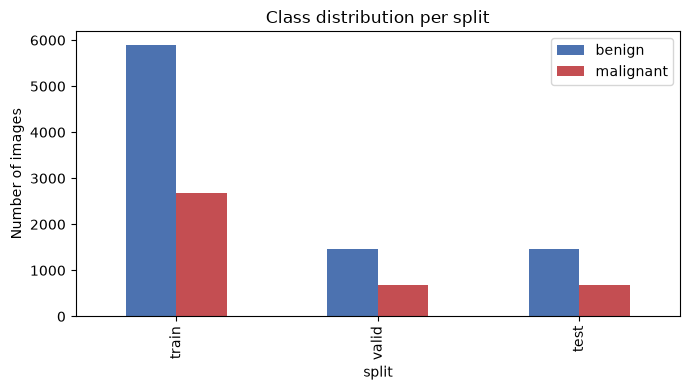

In [8]:
dist_rows = []
for name, df in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    counts = df["binary_label_name"].value_counts()
    dist_rows.append({
        "split": name,
        "benign": int(counts.get("Benign", 0)),
        "malignant": int(counts.get("Malignant", 0)),
        "malignant_pct": round(100 * counts.get("Malignant", 0) / len(df), 2),
    })

dist_df = pd.DataFrame(dist_rows)
print(dist_df)

fig, ax = plt.subplots(figsize=(7, 4))
dist_df.set_index("split")[["benign", "malignant"]].plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Class distribution per split")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "class_distribution.png", dpi=150)
plt.show()


## 6. Hair Removal Preprocessing (new)

Dermoscopic images in HAM10000 frequently have body hair crossing the lesion, which is a
pure artifact — it carries no diagnostic signal but can distract a CNN's low-level filters.
A common, cheap fix used in several skin-lesion papers is a **DullRazor-style** pipeline:

1. Convert to grayscale and apply a **blackhat morphological transform** (highlights thin
   dark structures like hairs against a lighter background).
2. **Threshold** the blackhat output to get a binary hair mask.
3. **Inpaint** the original image using that mask, replacing hair pixels with plausible
   neighboring skin/lesion texture.

This is applied *before* the augmentation pipeline, on the raw image, for every split
(train/valid/test) — it's a deterministic cleanup step, not an augmentation.

If OpenCV isn't installed, `CONFIG["hair_removal"]` was already forced to `False` above, and
the dataset class below simply skips this step.


In [9]:
def remove_hair(pil_image: Image.Image) -> Image.Image:
    '''DullRazor-style hair removal. Input/output are both PIL RGB images.'''
    image_bgr = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2BGR)
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)

    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    inpainted = cv2.inpaint(image_bgr, hair_mask, inpaintRadius=1, flags=cv2.INPAINT_TELEA)

    return Image.fromarray(cv2.cvtColor(inpainted, cv2.COLOR_BGR2RGB))


## 7. Data Augmentation (extended)

Kept everything from the earlier notebooks (flips, rotation, color jitter) and added:

- **`RandomResizedCrop`** instead of a plain `Resize` for training — adds scale/translation
  variance so the model doesn't memorize lesion size/position.
- **`RandomErasing`** (Cutout-style) after `ToTensor` — randomly blanks a small patch,
  forcing the model to rely on the whole lesion rather than one salient region.
- Evaluation/test transforms stay **deterministic** (plain resize, no randomness) — this
  matters for TTA later, where we explicitly control which transformations are applied.


In [10]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(CONFIG["img_size"], scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.08)),
])

eval_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Fixed-flip variants used only for test-time augmentation (see Section 15).
tta_transform_hflip = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

tta_transform_vflip = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomVerticalFlip(p=1.0),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


## 8. Dataset & DataLoader

In [11]:
class HAM10000BinaryDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform, apply_hair_removal: bool = False):
        self.image_paths = df["image_path"].tolist()
        self.labels = df["binary_label"].astype("float32").tolist()
        self.transform = transform
        self.apply_hair_removal = apply_hair_removal

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")
        if self.apply_hair_removal:
            image = remove_hair(image)
        image = self.transform(image)
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return image, label


train_dataset = HAM10000BinaryDataset(train_df, train_transform, CONFIG["hair_removal"])
valid_dataset = HAM10000BinaryDataset(valid_df, eval_transform, CONFIG["hair_removal"])
test_dataset = HAM10000BinaryDataset(test_df, eval_transform, CONFIG["hair_removal"])


### Training DataLoader — mild resampling (`soft_resample_power`)

`03b` used *full* inverse-frequency resampling (every epoch saw a perfectly 50/50 mix),
which pushed recall up but tanked precision. Here the resample strength is a tunable knob:
weight ∝ `1 / count^power`. At `power=0.5` the minority class is oversampled, but less
aggressively — the loss function (Class-Balanced Focal Loss, next section) does the rest of
the rebalancing work instead of relying on sampling alone.


In [12]:
class_counts = train_df["binary_label"].value_counts().sort_index()  # index 0=benign, 1=malignant
logger.info("Class counts (train): %s", class_counts.to_dict())

power = CONFIG["soft_resample_power"]
if power > 0:
    class_weights = 1.0 / (class_counts ** power)
    sample_weights = train_df["binary_label"].map(class_weights).values
    sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)
    train_loader = DataLoader(
        train_dataset, batch_size=CONFIG["batch_size"], sampler=sampler,
        num_workers=CONFIG["num_workers"], pin_memory=True,
    )
    logger.info("Training sampler: soft resampling (power=%.2f)", power)
else:
    train_loader = DataLoader(
        train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
        num_workers=CONFIG["num_workers"], pin_memory=True,
    )
    logger.info("Training sampler: plain shuffle (no resampling)")

valid_loader = DataLoader(
    valid_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], pin_memory=True,
)
test_loader = DataLoader(
    test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], pin_memory=True,
)

logger.info("Batches per epoch — train: %d, valid: %d, test: %d", len(train_loader), len(valid_loader), len(test_loader))


2026-07-22 12:07:44,986 | INFO | Class counts (train): {0: 5897, 1: 2690}
d:\SkinCancer_Project\SkinCancer_Project_env\Lib\site-packages\torch\utils\data\sampler.py:272: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  weights_tensor = torch.as_tensor(weights, dtype=torch.double)
2026-07-22 12:07:44,986 | INFO | Training sampler: soft resampling (power=0.50)
2026-07-22 12:07:44,986 | INFO | Batches per epoch — train: 269, valid: 68, test: 68


## 9. MixUp (new)

MixUp trains the model on **linear blends** of two random images and their labels
(`image = λ·img_a + (1-λ)·img_b`, `label = λ·label_a + (1-λ)·label_b`). It's a cheap,
well-established regularizer that smooths the decision boundary and tends to reduce
over-confident false positives — directly relevant to our precision problem.

It's applied **probabilistically** (`mixup_prob`) and **only in phases 1 and 2**
(`mixup_phases` in `CONFIG`) — turning it off for the final fine-tuning phase is standard
practice, since MixUp's label smoothing can blur the fine-grained decision boundary right
when we want the model to sharpen it.


In [13]:
def mixup_batch(images: torch.Tensor, labels: torch.Tensor, alpha: float):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    index = torch.randperm(images.size(0), device=images.device)
    mixed_images = lam * images + (1 - lam) * images[index]
    mixed_labels = lam * labels + (1 - lam) * labels[index]
    return mixed_images, mixed_labels


## 10. Model Definition

In [14]:
def build_model() -> nn.Module:
    model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

    # Freeze the entire pretrained backbone — Phase 1 trains only the new head.
    for param in model.features.parameters():
        param.requires_grad = False

    num_features = model.classifier.in_features  # 1024 for DenseNet121
    model.classifier = nn.Sequential(
        nn.Linear(num_features, 256),
        nn.BatchNorm1d(256),   # added: stabilizes head training, especially under MixUp/AMP
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 1),     # single logit; sigmoid applied inside the loss / at inference
    )
    return model


def unfreeze_blocks(model: nn.Module, block_prefixes: list) -> None:
    '''Unfreeze any backbone parameter whose name starts with one of block_prefixes.
    Called progressively across phases 2 and 3 — already-unfrozen blocks simply stay
    unfrozen, this only ever adds trainable parameters, never removes them.'''
    for name, param in model.features.named_parameters():
        if any(name.startswith(prefix) for prefix in block_prefixes):
            param.requires_grad = True

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    logger.info("Unfroze %s: %d / %d parameters now trainable (%.1f%%)",
                block_prefixes, n_trainable, n_total, 100 * n_trainable / n_total)


model = build_model().to(CONFIG["device"])
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
logger.info("Phase 1: %d / %d parameters trainable (%.1f%%)", n_trainable, n_total, 100 * n_trainable / n_total)


2026-07-22 12:07:45,215 | INFO | Phase 1: 263169 / 7217025 parameters trainable (3.6%)


## 11. Loss Function — Class-Balanced Focal Loss (new)

`03a` used Focal Loss with a hand-picked `alpha=0.75`. Here we compute the per-class weight
**automatically** from the training set using the **Class-Balanced Loss** formulation
(Cui et al., *"Class-Balanced Loss Based on Effective Number of Samples"*, CVPR 2019):

`effective_num_c = 1 − β^(n_c)`, `weight_c ∝ 1 / effective_num_c`

This is a more principled way to set the class weight than guessing a single `alpha` — it's
derived from how much *marginal* information an additional sample of a class is expected to
add, and it degrades gracefully (weight → uniform as `β → 0`, weight → inverse-frequency as
`β → 1`). We keep the `gamma` focusing term from the original Focal Loss on top of it.


In [15]:
class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, samples_per_class, beta: float = 0.9999, gamma: float = 2.0, device="cpu"):
        super().__init__()
        samples_per_class = np.array(samples_per_class, dtype=np.float64)
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(samples_per_class)  # normalize to sum to n_classes

        self.class_weights = torch.tensor(weights, dtype=torch.float32, device=device)  # [w_benign, w_malignant]
        self.gamma = gamma
        logger.info("Class-Balanced weights (benign, malignant): %s", weights.round(4).tolist())

    def forward(self, logits, targets):
        alpha_t = targets * self.class_weights[1] + (1 - targets) * self.class_weights[0]
        bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_term = alpha_t * (1 - p_t) ** self.gamma * bce_loss
        return focal_term.mean()


samples_per_class = [class_counts.get(0, 0), class_counts.get(1, 0)]  # [benign, malignant]
criterion = ClassBalancedFocalLoss(
    samples_per_class, beta=CONFIG["cb_beta"], gamma=CONFIG["focal_gamma"], device=CONFIG["device"],
)


2026-07-22 12:07:45,219 | INFO | Class-Balanced weights (benign, malignant): [0.6923, 1.3077]


## 12. Optimizer & Scheduler — discriminative learning rates (new)

Instead of one learning rate for the whole model, the optimizer now uses **two parameter
groups**: a higher LR for the (randomly-initialized) classification head, and a much lower
LR for any unfrozen backbone layers, which are pretrained and should only be nudged gently.
This is standard practice in transfer learning and avoids the fine-tuned backbone layers
"catching up" too fast and forgetting their ImageNet features.

We also switched `Adam` → **`AdamW`**, which decouples weight decay from the gradient
update (the "correct" way to do L2 regularization with adaptive optimizers — see Loshchilov
& Hutter, 2019) — `Adam` folds weight decay into the gradient itself, which interacts
poorly with the per-parameter learning rate adaptation.


In [16]:
def build_optimizer(model: nn.Module, head_lr: float, backbone_lr: float = None) -> optim.Optimizer:
    head_params = list(model.classifier.parameters())
    backbone_params = [p for p in model.features.parameters() if p.requires_grad]

    param_groups = [{"params": head_params, "lr": head_lr}]
    if backbone_params:
        param_groups.append({"params": backbone_params, "lr": backbone_lr or head_lr * 0.1})

    return optim.AdamW(param_groups, weight_decay=CONFIG["weight_decay"])


def build_scheduler(optimizer: optim.Optimizer) -> optim.lr_scheduler.ReduceLROnPlateau:
    return optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=CONFIG["scheduler_factor"], patience=CONFIG["scheduler_patience"]
    )


## 13. Training Loop — AMP + gradient clipping + MixUp (extended)

`run_epoch` now:
- Runs the forward pass under `torch.cuda.amp.autocast` (**mixed precision**) when
  `CONFIG["use_amp"]` is on — roughly 1.5-2x faster on modern NVIDIA GPUs (like the RTX 2000
  Ada) with negligible accuracy impact, since gradients are still accumulated in FP32 via
  `GradScaler`.
- Optionally applies **MixUp** to a fraction of training batches (`mixup_prob`), but always
  computes and logs metrics against the **original, un-mixed labels** — MixUp only affects
  what the loss function sees, never the AUC/accuracy bookkeeping.
- Applies **gradient clipping** (`grad_clip_norm`) before the optimizer step, which prevents
  occasional large gradients (common early in fine-tuning newly-unfrozen layers) from
  destabilizing training.


In [17]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None, device=None,
              use_amp=False, mixup_alpha=0.0, mixup_prob=0.0, grad_clip=None):
    device = device or CONFIG["device"]
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    running_loss = 0.0
    all_labels, all_probs = [], []

    torch.set_grad_enabled(is_training)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device).unsqueeze(1)
        loss_labels = labels

        if is_training and mixup_alpha > 0 and random.random() < mixup_prob:
            images, loss_labels = mixup_batch(images, labels, mixup_alpha)

        if is_training:
            optimizer.zero_grad()

        with autocast(enabled=use_amp):
            logits = model(images)
            loss = criterion(logits, loss_labels)

        if is_training:
            scaler.scale(loss).backward()
            if grad_clip is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()

        running_loss += loss.item() * images.size(0)
        all_labels.extend(labels.detach().cpu().numpy().flatten())
        all_probs.extend(torch.sigmoid(logits).detach().float().cpu().numpy().flatten())
    torch.set_grad_enabled(True)

    epoch_loss = running_loss / len(loader.dataset)
    epoch_auc = roc_auc_score(all_labels, all_probs)
    return epoch_loss, epoch_auc, np.array(all_labels), np.array(all_probs)


In [18]:
def train_phase(model, phase_name, n_epochs, optimizer, scheduler, train_loader, valid_loader,
                 criterion, history, best_state, scaler, use_mixup: bool):
    epochs_without_improvement = 0
    mixup_alpha = CONFIG["mixup_alpha"] if use_mixup else 0.0
    mixup_prob = CONFIG["mixup_prob"] if use_mixup else 0.0

    for epoch in range(1, n_epochs + 1):
        start = time.time()

        train_loss, train_auc, train_labels, train_probs = run_epoch(
            model, train_loader, criterion, optimizer=optimizer, scaler=scaler,
            use_amp=CONFIG["use_amp"], mixup_alpha=mixup_alpha, mixup_prob=mixup_prob,
            grad_clip=CONFIG["grad_clip_norm"],
        )
        val_loss, val_auc, val_labels, val_probs = run_epoch(
            model, valid_loader, criterion, optimizer=None, use_amp=CONFIG["use_amp"],
        )
        # Accuracy at a fixed 0.5 cutoff, for the training-curve plots only - the real operating
        # threshold is chosen later (Section 17) from calibrated validation probabilities.
        train_acc = accuracy_score(train_labels, (train_probs >= 0.5).astype(int))
        val_acc = accuracy_score(val_labels, (val_probs >= 0.5).astype(int))

        scheduler.step(val_auc)
        elapsed = time.time() - start

        history.append({
            "phase": phase_name, "epoch": epoch,
            "train_loss": train_loss, "train_auc": train_auc, "train_acc": train_acc,
            "val_loss": val_loss, "val_auc": val_auc, "val_acc": val_acc,
            "lr_head": optimizer.param_groups[0]["lr"],
            "lr_backbone": optimizer.param_groups[1]["lr"] if len(optimizer.param_groups) > 1 else None,
            "seconds": round(elapsed, 1),
        })

        logger.info(
            "[%s] epoch %d/%d | train_loss=%.4f train_auc=%.4f train_acc=%.4f | val_loss=%.4f val_auc=%.4f val_acc=%.4f | %.1fs",
            phase_name, epoch, n_epochs, train_loss, train_auc, train_acc, val_loss, val_auc, val_acc, elapsed,
        )

        if val_auc > best_state["val_auc"]:
            best_state["val_auc"] = val_auc
            best_state["model_state"] = copy.deepcopy(model.state_dict())
            best_state["epoch"] = epoch
            best_state["phase"] = phase_name
            epochs_without_improvement = 0
            logger.info("  -> new best model (val_auc=%.4f)", val_auc)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
                logger.info("  -> early stopping (%d epochs without improvement)", epochs_without_improvement)
                break

    last_model_state = copy.deepcopy(model.state_dict())
    last_epoch_info = history[-1]
    return history, best_state, last_model_state, last_epoch_info


## 14. Run the Three Training Phases

1. **Phase 1 — head only.** Backbone fully frozen, train the new classification head.
2. **Phase 2 — last dense block.** Unfreeze `denseblock4` + `norm5` (same as the earlier
   notebooks), fine-tune with a low backbone LR.
3. **Phase 3 (new) — last two dense blocks.** Additionally unfreeze `denseblock3`, with an
   even lower LR. This gives the model access to slightly more task-specific mid-level
   features without touching the earliest, most generic ImageNet layers — a middle ground
   between the 2-phase approach (which stopped at one block) and full fine-tuning (which
   risks overfitting on ~7-8k training images).

MixUp is active in phases 1 and 2 (per `CONFIG["mixup_phases"]`) and switched off for phase
3, per the reasoning in Section 9.


In [19]:
history = []
best_state = {"val_auc": -1.0, "model_state": None, "epoch": None, "phase": None}
scaler = GradScaler(enabled=CONFIG["use_amp"])

# ---- Phase 1: frozen backbone, train the head only -----------------------
logger.info("=== Phase 1: training classification head (backbone frozen) ===")
optimizer1 = build_optimizer(model, head_lr=CONFIG["phase1_head_lr"])
scheduler1 = build_scheduler(optimizer1)
history, best_state, last_model_state, last_epoch_info = train_phase(
    model, "phase1_head_only", CONFIG["phase1_epochs"], optimizer1, scheduler1,
    train_loader, valid_loader, criterion, history, best_state, scaler,
    use_mixup=("phase1_head_only" in CONFIG["mixup_phases"]),
)

# ---- Phase 2: unfreeze last dense block -----------------------------------
logger.info("=== Phase 2: fine-tuning last dense block (denseblock4) ===")
unfreeze_blocks(model, ["denseblock4", "norm5"])
optimizer2 = build_optimizer(model, head_lr=CONFIG["phase2_head_lr"], backbone_lr=CONFIG["phase2_backbone_lr"])
scheduler2 = build_scheduler(optimizer2)
history, best_state, last_model_state, last_epoch_info = train_phase(
    model, "phase2_finetune_block4", CONFIG["phase2_epochs"], optimizer2, scheduler2,
    train_loader, valid_loader, criterion, history, best_state, scaler,
    use_mixup=("phase2_finetune_block4" in CONFIG["mixup_phases"]),
)

# ---- Phase 3: unfreeze last two dense blocks (new) ------------------------
logger.info("=== Phase 3: fine-tuning last two dense blocks (denseblock3 + denseblock4) ===")
unfreeze_blocks(model, ["denseblock3", "denseblock4", "norm5"])
optimizer3 = build_optimizer(model, head_lr=CONFIG["phase3_head_lr"], backbone_lr=CONFIG["phase3_backbone_lr"])
scheduler3 = build_scheduler(optimizer3)
history, best_state, last_model_state, last_epoch_info = train_phase(
    model, "phase3_finetune_block3_4", CONFIG["phase3_epochs"], optimizer3, scheduler3,
    train_loader, valid_loader, criterion, history, best_state, scaler,
    use_mixup=("phase3_finetune_block3_4" in CONFIG["mixup_phases"]),
)

logger.info("Best validation AUC: %.4f (phase=%s, epoch=%d)", best_state["val_auc"], best_state["phase"], best_state["epoch"])

# Restore the best checkpoint seen across all three phases before evaluating / saving.
model.load_state_dict(best_state["model_state"])


C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\3488559245.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=CONFIG["use_amp"])
2026-07-22 12:07:45,262 | INFO | === Phase 1: training classification head (backbone frozen) ===
C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\255504171.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=use_amp):
C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\255504171.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=use_amp):
2026-07-22 12:12:09,075 | INFO | [phase1_head_only] epoch 1/12 | train_loss=0.1166 train_auc=0.7974 train_acc=0.7174 | val_loss=0.0977 val_auc=0.8912 val_acc=0.7569 | 263.8s
2026-07-22 12:12:09,

<All keys matched successfully>

## 15. Training Curves

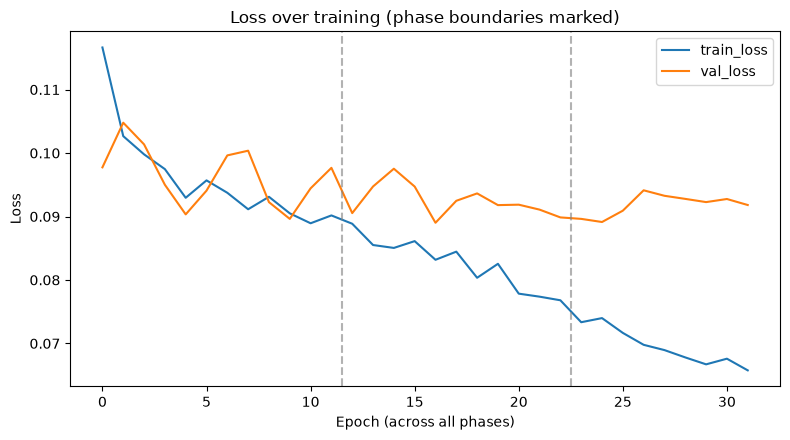

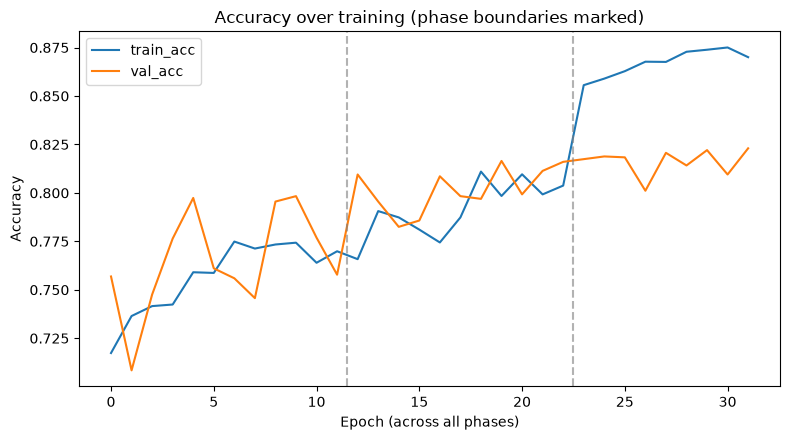

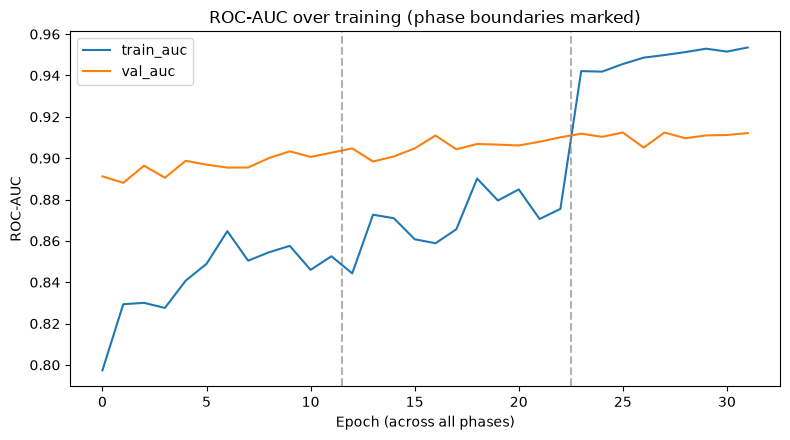

In [20]:
history_df = pd.DataFrame(history)
history_df.to_csv(CONFIG["output_dir"] / "training_history.csv", index=False)

phase_boundaries = history_df.reset_index().groupby("phase")["index"].max().values[:-1] + 0.5

# Three separate curves (loss, accuracy, AUC), each train+val - matches the other two V2
# baselines exactly, one file per metric under plots/training_curves/.
for metric, ylabel, filename in [
    ("loss", "Loss", "loss_curve.png"),
    ("acc", "Accuracy", "accuracy_curve.png"),
    ("auc", "ROC-AUC", "auc_curve.png"),
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(history_df.index, history_df[f"train_{metric}"], label=f"train_{metric}")
    ax.plot(history_df.index, history_df[f"val_{metric}"], label=f"val_{metric}")
    for b in phase_boundaries:
        ax.axvline(b, color="gray", linestyle="--", alpha=0.6)
    ax.set_title(f"{ylabel} over training (phase boundaries marked)")
    ax.set_xlabel("Epoch (across all phases)"); ax.set_ylabel(ylabel)
    ax.legend()
    fig.tight_layout()
    fig.savefig(TRAINING_CURVES_DIR / filename, dpi=150)
    plt.show()


## 16. Test-Time Augmentation (new)

Instead of a single forward pass on the resized test image, we run **three** deterministic
views — the original resize, a horizontal flip, and a vertical flip — and **average the
predicted probabilities**. Lesion orientation carries no diagnostic meaning, so this is a
"free" way to reduce prediction variance without any extra training: it's effectively a
3-model ensemble that shares one set of weights.


In [21]:
def predict_with_tta(model, df, transform_list, device, apply_hair_removal, batch_size, num_workers, use_amp):
    all_probs = []
    model.eval()
    for transform in transform_list:
        dataset = HAM10000BinaryDataset(df, transform, apply_hair_removal)
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
        probs = []
        with torch.no_grad():
            for images, _ in loader:
                images = images.to(device)
                with autocast(enabled=use_amp):
                    logits = model(images)
                probs.extend(torch.sigmoid(logits).float().cpu().numpy().flatten())
        all_probs.append(np.array(probs))
    return np.mean(all_probs, axis=0)


tta_transforms = [eval_transform, tta_transform_hflip, tta_transform_vflip]

if CONFIG["use_tta"]:
    valid_probs = predict_with_tta(model, valid_df, tta_transforms, CONFIG["device"],
                                    CONFIG["hair_removal"], CONFIG["batch_size"], CONFIG["num_workers"], CONFIG["use_amp"])
    test_probs = predict_with_tta(model, test_df, tta_transforms, CONFIG["device"],
                                   CONFIG["hair_removal"], CONFIG["batch_size"], CONFIG["num_workers"], CONFIG["use_amp"])
else:
    _, _, _, valid_probs = run_epoch(model, valid_loader, criterion, use_amp=CONFIG["use_amp"])
    _, _, _, test_probs = run_epoch(model, test_loader, criterion, use_amp=CONFIG["use_amp"])

valid_labels = valid_df["binary_label"].astype("float32").values
test_labels = test_df["binary_label"].astype("float32").values

logger.info("Test ROC AUC (%s): %.4f", "with TTA" if CONFIG["use_tta"] else "no TTA", roc_auc_score(test_labels, test_probs))


C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\311436051.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=use_amp):
C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\311436051.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=use_amp):
C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\311436051.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=use_amp):
C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\311436051.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=use_amp):
C:\Users\S-GF-L1-D35\AppData\Local\Temp\ipykernel_35580\311436051.py:11: FutureW

## 16b. Probability Calibration (Platt Scaling, new)

TTA gives raw probabilities that are not necessarily well-calibrated (the model can be
systematically over- or under-confident). Platt scaling fits a 1-D logistic regression
(`calibrated = sigmoid(A * raw_prob + B)`) on the **validation set only**, then applies it to
both validation and test probabilities. This is a standard, low-risk calibration step done
*before* threshold selection and *before* combining models in the Soft Voting Ensemble - so the
ensemble averages probabilities that are on a comparable, calibrated scale across all three
backbones instead of averaging however each model happens to be over/under-confident.

`valid_probs` and `test_probs` are overwritten in place with their calibrated versions, so every
cell below this one (threshold selection, metrics, curves, predictions.csv) automatically uses
calibrated probabilities without needing further changes.

In [22]:
def fit_platt_calibrator(val_probs: np.ndarray, val_labels: np.ndarray) -> LogisticRegression:
    """Platt scaling: fits calibrated_prob = sigmoid(A * raw_prob + B) via logistic regression
    on the validation set's raw probabilities vs true labels."""
    calibrator = LogisticRegression(C=1e10, solver="lbfgs")  # effectively unregularized -> classic Platt scaling
    calibrator.fit(val_probs.reshape(-1, 1), val_labels.astype(int))
    return calibrator


def apply_calibrator(calibrator: LogisticRegression, probs: np.ndarray) -> np.ndarray:
    return calibrator.predict_proba(probs.reshape(-1, 1))[:, 1]


platt_calibrator = fit_platt_calibrator(valid_probs, valid_labels)
logger.info("Platt scaling fit on validation set: A=%.4f, B=%.4f",
            platt_calibrator.coef_[0][0], platt_calibrator.intercept_[0])

raw_valid_probs, raw_test_probs = valid_probs.copy(), test_probs.copy()  # kept for reference/debugging only
valid_probs = apply_calibrator(platt_calibrator, raw_valid_probs)
test_probs = apply_calibrator(platt_calibrator, raw_test_probs)

logger.info("Brier score before calibration -> valid: %.4f, test: %.4f",
            brier_score_loss(valid_labels, raw_valid_probs), brier_score_loss(test_labels, raw_test_probs))
logger.info("Brier score after calibration  -> valid: %.4f, test: %.4f",
            brier_score_loss(valid_labels, valid_probs), brier_score_loss(test_labels, test_probs))


2026-07-22 14:31:54,913 | INFO | Platt scaling fit on validation set: A=9.0074, B=-5.3255
2026-07-22 14:31:54,913 | INFO | Brier score before calibration -> valid: 0.1279, test: 0.1264
2026-07-22 14:31:54,913 | INFO | Brier score after calibration  -> valid: 0.1076, test: 0.1070


## 17. Threshold Selection — tuned on validation set (new)

The earlier notebooks tried two arbitrary thresholds (0.5 and 0.3) **directly on the test
set** — which is a subtle form of leakage (you're allowed to look at the test set exactly
once, for a single final number). Here we search for good thresholds on the **validation
set only**, then apply the chosen threshold(s) to the test set a single time.

We report two operating points, since precision and recall trade off against each other and
the "right" choice is a clinical/business decision, not a modeling one:

- **F1-optimal threshold** — the best balance between precision and recall.
- **High-sensitivity threshold** — the highest threshold that still achieves at least
  `CONFIG["high_sensitivity_target_recall"]` (default 90%) recall on malignant cases, which
  is closer to how a real screening tool would be tuned (catch almost everything, accept
  more false alarms — those get resolved by a follow-up biopsy, not by the model).


2026-07-22 14:31:55,063 | INFO | F1-optimal threshold (from validation set): 0.41 (val F1=0.7680)
2026-07-22 14:31:55,063 | INFO | High-sensitivity threshold (from validation set, target recall>=90%): 0.21


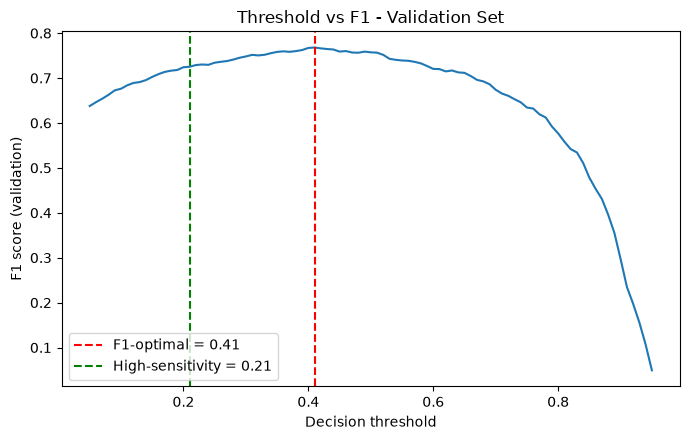

In [23]:
def find_f1_optimal_threshold(labels, probs):
    thresholds = np.arange(0.05, 0.96, 0.01)
    best_t, best_f1 = 0.5, -1.0
    for t in thresholds:
        preds = (probs >= t).astype(int)
        f1 = f1_score(labels, preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return round(float(best_t), 2), best_f1


def find_high_sensitivity_threshold(labels, probs, target_recall):
    thresholds = np.arange(0.95, 0.02, -0.01)
    chosen = float(thresholds[-1])
    for t in thresholds:
        preds = (probs >= t).astype(int)
        r = recall_score(labels, preds, zero_division=0)
        if r >= target_recall:
            chosen = float(t)
            break
    return round(chosen, 2)


f1_threshold, f1_at_threshold = find_f1_optimal_threshold(valid_labels, valid_probs)
high_sens_threshold = find_high_sensitivity_threshold(valid_labels, valid_probs, CONFIG["high_sensitivity_target_recall"])

logger.info("F1-optimal threshold (from validation set): %.2f (val F1=%.4f)", f1_threshold, f1_at_threshold)
logger.info("High-sensitivity threshold (from validation set, target recall>=%.0f%%): %.2f",
            CONFIG["high_sensitivity_target_recall"] * 100, high_sens_threshold)


# --- Threshold vs F1 curve (validation set) ------------------------------------------------
_thresh_sweep = np.arange(0.05, 0.96, 0.01)
_f1_sweep = [f1_score(valid_labels, (valid_probs >= t).astype(int), zero_division=0) for t in _thresh_sweep]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(_thresh_sweep, _f1_sweep)
ax.axvline(f1_threshold, color="red", linestyle="--", label=f"F1-optimal = {f1_threshold:.2f}")
ax.axvline(high_sens_threshold, color="green", linestyle="--", label=f"High-sensitivity = {high_sens_threshold:.2f}")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("F1 score (validation)")
ax.set_title("Threshold vs F1 - Validation Set")
ax.legend()
fig.tight_layout()
fig.savefig(TRAINING_CURVES_DIR / "threshold_vs_f1_curve.png", dpi=150)
plt.show()

## 18. Extended Performance Evaluation (new metrics)

In [24]:
def compute_extended_metrics(labels, probs, threshold) -> dict:
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds).ravel()
    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall_sensitivity": recall_score(labels, preds, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "npv": tn / (tn + fn) if (tn + fn) > 0 else 0.0,
        "f1_score": f1_score(labels, preds, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(labels, preds),
        "mcc": matthews_corrcoef(labels, preds),
        "roc_auc": roc_auc_score(labels, probs),
        "brier_score": brier_score_loss(labels, probs),
    }


metrics_default = compute_extended_metrics(test_labels, test_probs, 0.5)
metrics_f1_optimal = compute_extended_metrics(test_labels, test_probs, f1_threshold)
metrics_high_sensitivity = compute_extended_metrics(test_labels, test_probs, high_sens_threshold)

print("Test metrics @ threshold 0.5 (for direct comparison with 03a/03b):")
print(json.dumps(metrics_default, indent=2))
print(f"\nTest metrics @ F1-optimal threshold ({f1_threshold}):")
print(json.dumps(metrics_f1_optimal, indent=2))
print(f"\nTest metrics @ high-sensitivity threshold ({high_sens_threshold}, target recall >= {CONFIG['high_sensitivity_target_recall']:.0%}):")
print(json.dumps(metrics_high_sensitivity, indent=2))


Test metrics @ threshold 0.5 (for direct comparison with 03a/03b):
{
  "threshold": 0.5,
  "accuracy": 0.8462971588262692,
  "precision": 0.7567164179104477,
  "recall_sensitivity": 0.7522255192878339,
  "specificity": 0.8893414799728445,
  "npv": 0.8869329722410291,
  "f1_score": 0.7544642857142857,
  "balanced_accuracy": 0.8207834996303391,
  "mcc": 0.6426073511993531,
  "roc_auc": 0.9174513145622188,
  "brier_score": 0.10695253312587738
}

Test metrics @ F1-optimal threshold (0.41):
{
  "threshold": 0.41,
  "accuracy": 0.83977643223102,
  "precision": 0.7188328912466844,
  "recall_sensitivity": 0.8041543026706232,
  "specificity": 0.8560760353021045,
  "npv": 0.905240488155061,
  "f1_score": 0.7591036414565826,
  "balanced_accuracy": 0.8301151689863638,
  "mcc": 0.6418973268383322,
  "roc_auc": 0.9174513145622188,
  "brier_score": 0.10695253312587738
}

Test metrics @ high-sensitivity threshold (0.21, target recall >= 90%):
{
  "threshold": 0.21,
  "accuracy": 0.7969259431765254,
  

In [25]:
preds_f1 = (test_probs >= f1_threshold).astype(int)
print(f"Classification report @ F1-optimal threshold ({f1_threshold}):")
print(classification_report(test_labels, preds_f1, target_names=["benign", "malignant"]))

report_dict = classification_report(test_labels, preds_f1, target_names=["benign", "malignant"], output_dict=True)
with open(CONFIG["output_dir"] / "classification_report_f1_optimal.json", "w") as f:
    json.dump(report_dict, f, indent=2)


Classification report @ F1-optimal threshold (0.41):
              precision    recall  f1-score   support

      benign       0.91      0.86      0.88      1473
   malignant       0.72      0.80      0.76       674

    accuracy                           0.84      2147
   macro avg       0.81      0.83      0.82      2147
weighted avg       0.85      0.84      0.84      2147



## 19. Confusion Matrices — both operating points

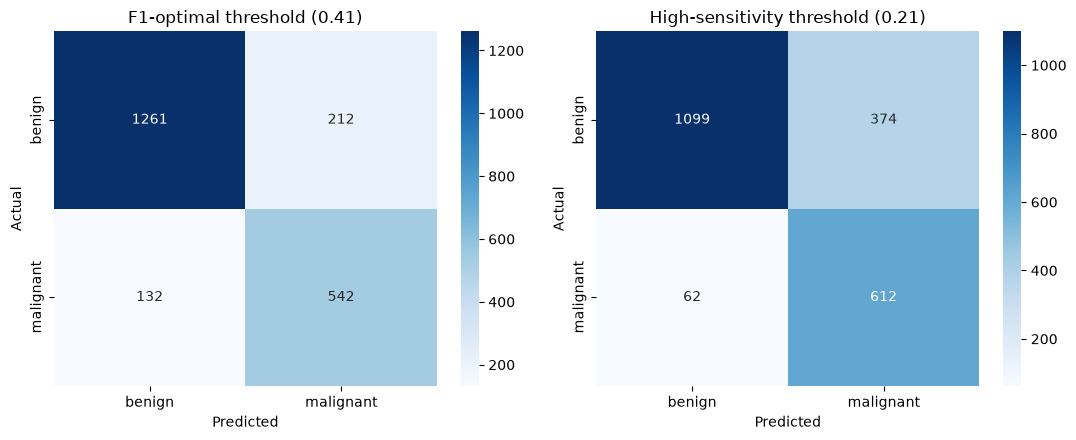

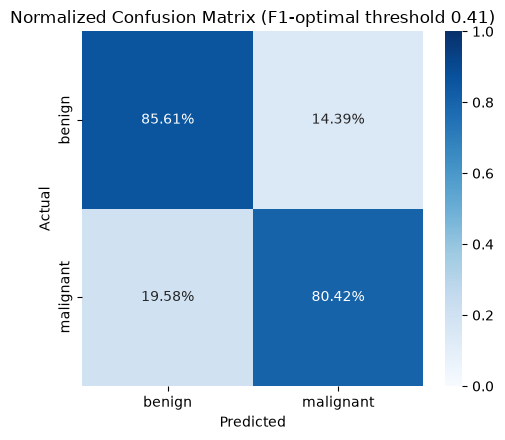

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_f1 = confusion_matrix(test_labels, (test_probs >= f1_threshold).astype(int))
sns.heatmap(cm_f1, annot=True, fmt="d", cmap="Blues", xticklabels=["benign", "malignant"],
            yticklabels=["benign", "malignant"], ax=axes[0])
axes[0].set_title(f"F1-optimal threshold ({f1_threshold})")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

cm_hs = confusion_matrix(test_labels, (test_probs >= high_sens_threshold).astype(int))
sns.heatmap(cm_hs, annot=True, fmt="d", cmap="Blues", xticklabels=["benign", "malignant"],
            yticklabels=["benign", "malignant"], ax=axes[1])
axes[1].set_title(f"High-sensitivity threshold ({high_sens_threshold})")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(CONFUSION_MATRICES_DIR / "confusion_matrix.png", dpi=150)
plt.show()

cm_normalized = cm_f1.astype(float) / cm_f1.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=["benign", "malignant"],
            yticklabels=["benign", "malignant"], ax=ax, vmin=0, vmax=1)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Normalized Confusion Matrix (F1-optimal threshold {f1_threshold})")
fig.tight_layout()
fig.savefig(CONFUSION_MATRICES_DIR / "normalized_confusion_matrix.png", dpi=150)
plt.show()


## 20. ROC Curve & Precision-Recall Curve

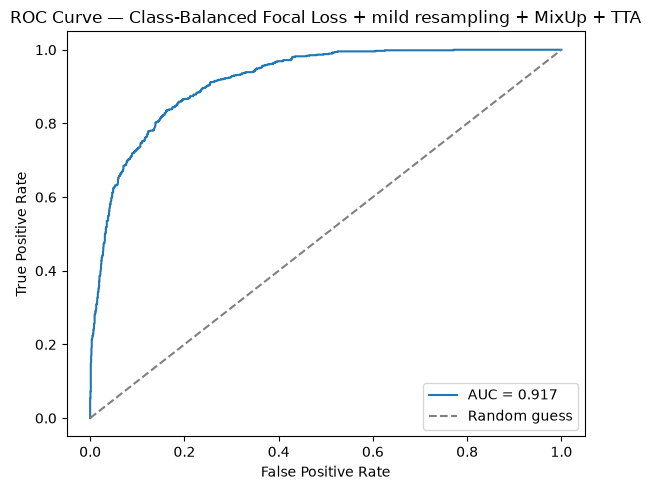

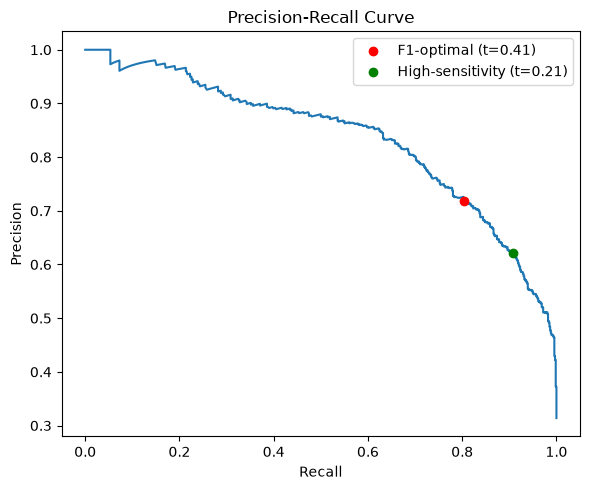

In [27]:
fpr, tpr, _ = roc_curve(test_labels, test_probs)
precision_vals, recall_vals, _ = precision_recall_curve(test_labels, test_probs)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"AUC = {metrics_default['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title(f"ROC Curve — {CONFIG['imbalance_method']}")
ax.legend()
fig.tight_layout()
fig.savefig(ROC_PR_DIR / "roc_curve.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_vals, precision_vals)
ax.scatter([metrics_f1_optimal["recall_sensitivity"]], [metrics_f1_optimal["precision"]],
           color="red", zorder=5, label=f"F1-optimal (t={f1_threshold})")
ax.scatter([metrics_high_sensitivity["recall_sensitivity"]], [metrics_high_sensitivity["precision"]],
           color="green", zorder=5, label=f"High-sensitivity (t={high_sens_threshold})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend()
fig.tight_layout()
fig.savefig(ROC_PR_DIR / "precision_recall_curve.png", dpi=150)
plt.show()


## 21. Calibration Curve (new)

AUC and F1 tell you whether the model *ranks* malignant cases above benign ones correctly,
but not whether a predicted probability of, say, 0.8 actually corresponds to an ~80% chance
of malignancy. That's **calibration**, and it matters if these probabilities are ever shown
to a clinician as a "confidence score" rather than just thresholded into a binary decision.
A perfectly calibrated model's curve sits on the diagonal.


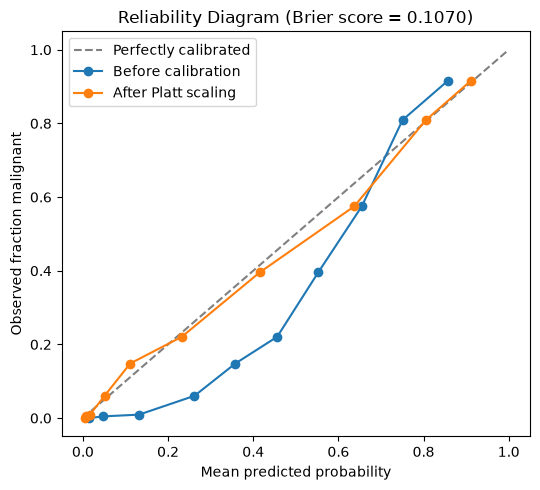

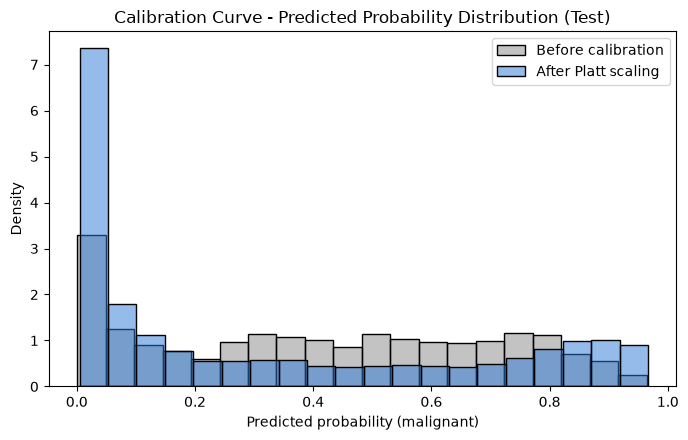

In [28]:
# Reliability diagram: before (raw TTA probs) vs after (Platt-scaled) calibration on the test
# set - same comparison style as the DINOv2/EfficientNet-B3 V2 notebooks.
frac_pos_before, mean_pred_before = calibration_curve(test_labels, raw_test_probs, n_bins=10, strategy="quantile")
frac_pos_after, mean_pred_after = calibration_curve(test_labels, test_probs, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
ax.plot(mean_pred_before, frac_pos_before, marker="o", label="Before calibration")
ax.plot(mean_pred_after, frac_pos_after, marker="o", label="After Platt scaling")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction malignant")
ax.set_title(f"Reliability Diagram (Brier score = {metrics_default['brier_score']:.4f})")
ax.legend()
fig.tight_layout()
fig.savefig(CALIBRATION_DIR / "reliability_diagram.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(raw_test_probs, bins=20, color="#888", alpha=0.5, label="Before calibration", ax=ax, stat="density")
sns.histplot(test_probs, bins=20, color="#2a78d6", alpha=0.5, label="After Platt scaling", ax=ax, stat="density")
ax.set_xlabel("Predicted probability (malignant)"); ax.set_ylabel("Density")
ax.set_title("Calibration Curve - Predicted Probability Distribution (Test)")
ax.legend()
fig.tight_layout()
fig.savefig(CALIBRATION_DIR / "calibration_curve.png", dpi=150)
plt.show()


## 22. Save Per-Image Predictions

In [29]:
# Soft Voting Ensemble contract: image_id, true_label, predicted_label, probability_benign,
# probability_malignant - identical schema/column names AND identical verification logic to
# every other baseline notebook in this project (Binary_DINOv2_Baseline.ipynb,
# Binary_EfficientNetB3_Baseline.ipynb), so the three predictions.csv files are directly
# mergeable by image_id with no manual preprocessing. `predicted_label` uses the F1-optimal
# threshold chosen on validation; the high-sensitivity variant and image_path are kept as extra,
# non-contract columns for reference.
def finalize_and_save_predictions(predictions_df: pd.DataFrame, test_df: pd.DataFrame, output_path: Path) -> pd.DataFrame:
    required_columns = {"image_id", "true_label", "predicted_label", "probability_benign", "probability_malignant"}
    missing_columns = required_columns - set(predictions_df.columns)
    if missing_columns:
        raise RuntimeError(f"predictions.csv is missing required column(s): {missing_columns}")

    if predictions_df["image_id"].duplicated().any():
        dup_ids = predictions_df.loc[predictions_df["image_id"].duplicated(), "image_id"].tolist()
        raise RuntimeError(f"Duplicate image_id value(s) found in predictions: {dup_ids}")

    predicted_ids = set(predictions_df["image_id"])
    expected_ids = set(test_df["image_id"])
    if predicted_ids != expected_ids:
        missing = expected_ids - predicted_ids
        extra = predicted_ids - expected_ids
        raise RuntimeError(
            f"Predictions do not correspond exactly to the test metadata. "
            f"Missing {len(missing)} (e.g. {list(missing)[:5]}), extra {len(extra)} (e.g. {list(extra)[:5]})."
        )

    # Align explicitly by image_id (never rely on row/iteration order), then sort.
    aligned = test_df[["image_id"]].merge(predictions_df, on="image_id", how="left", validate="one_to_one")
    aligned = aligned.sort_values("image_id").reset_index(drop=True)

    aligned.to_csv(output_path, index=False)
    logger.info("Saved predictions.csv (%d rows, verified + aligned + sorted by image_id) to %s", len(aligned), output_path)
    return aligned


predictions_df = pd.DataFrame({
    "image_id": test_df["image_id"].values,
    "true_label": test_labels.astype(int),
    "predicted_label": (test_probs >= f1_threshold).astype(int),
    "probability_benign": (1 - test_probs).astype(float),
    "probability_malignant": test_probs.astype(float),
    "predicted_label_high_sensitivity": (test_probs >= high_sens_threshold).astype(int),
    "image_path": test_df["image_path"].values,
})

predictions_path = CONFIG["output_dir"] / "predictions" / "predictions.csv"
predictions_df = finalize_and_save_predictions(predictions_df, test_df, predictions_path)


# Also save calibrated validation-set predictions with the same schema. The Soft Voting Ensemble
# notebook needs these (not just test predictions) to choose its own F1-optimal threshold on a
# validation set - never on test - exactly like each individual baseline notebook does.
val_predictions_df = pd.DataFrame({
    "image_id": valid_df["image_id"].values,
    "true_label": valid_labels.astype(int),
    "predicted_label": (valid_probs >= f1_threshold).astype(int),
    "probability_benign": (1 - valid_probs).astype(float),
    "probability_malignant": valid_probs.astype(float),
})
val_predictions_path = CONFIG["output_dir"] / "predictions" / "val_predictions.csv"
val_predictions_df = finalize_and_save_predictions(val_predictions_df, valid_df, val_predictions_path)

2026-07-22 14:31:56,281 | INFO | Saved predictions.csv (2147 rows, verified + aligned + sorted by image_id) to D:\SkinCancer_Project\outputs\binary\Binary_DenseNet121_Baseline_V2\predictions\predictions.csv
2026-07-22 14:31:56,298 | INFO | Saved predictions.csv (2147 rows, verified + aligned + sorted by image_id) to D:\SkinCancer_Project\outputs\binary\Binary_DenseNet121_Baseline_V2\predictions\val_predictions.csv


## 22b. Error Analysis

Splits test predictions (at the F1-optimal threshold) into True Positive / True Negative /
False Positive / False Negative. For each category: a CSV (under `error_analysis/`), a sample
image grid (under `plots/error_analysis/`), and summary statistics - identical structure to the
DINOv2 and EfficientNet-B3 V2 notebooks.

In [30]:
def categorize(row) -> str:
    if row["true_label"] == 1 and row["predicted_label"] == 1:
        return "TP"
    if row["true_label"] == 0 and row["predicted_label"] == 0:
        return "TN"
    if row["true_label"] == 0 and row["predicted_label"] == 1:
        return "FP"
    return "FN"


predictions_df["category"] = predictions_df.apply(categorize, axis=1)

CATEGORY_GRID_FILENAMES = {
    "TP": "true_positive_grid.png", "TN": "true_negative_grid.png",
    "FP": "false_positive_grid.png", "FN": "false_negative_grid.png",
}

category_stats = {}
for category in ["TP", "TN", "FP", "FN"]:
    subset = predictions_df[predictions_df["category"] == category]
    subset.to_csv(ERROR_ANALYSIS_DIR / f"{category}.csv", index=False)  # CSVs: top-level error_analysis/

    category_stats[category] = {
        "count": int(len(subset)),
        "mean_probability_malignant": float(subset["probability_malignant"].mean()) if len(subset) else None,
    }

    sample = subset.head(16)
    if len(sample) > 0:
        n_cols = 4
        n_rows = int(np.ceil(len(sample) / n_cols))
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
        axes = np.atleast_1d(axes).flatten()
        for ax, (_, row) in zip(axes, sample.iterrows()):
            try:
                ax.imshow(Image.open(row["image_path"]).convert("RGB"))
            except Exception:
                pass
            ax.set_title(f"{row['image_id']}\np(mal)={row['probability_malignant']:.2f}", fontsize=8)
            ax.axis("off")
        for ax in axes[len(sample):]:
            ax.axis("off")
        fig.suptitle(f"{category} - sample of {len(sample)} (of {len(subset)} total)")
        fig.tight_layout()
        # Grids: plots/error_analysis/, with the required descriptive filenames.
        fig.savefig(PLOTS_ERROR_ANALYSIS_DIR / CATEGORY_GRID_FILENAMES[category], dpi=150)
        plt.close(fig)

with open(ERROR_ANALYSIS_DIR / "error_analysis_stats.json", "w") as f:
    json.dump(category_stats, f, indent=2)

logger.info("Error analysis category counts: %s", {k: v["count"] for k, v in category_stats.items()})
category_stats


2026-07-22 14:32:14,912 | INFO | Error analysis category counts: {'TP': 542, 'TN': 1261, 'FP': 212, 'FN': 132}


{'TP': {'count': 542, 'mean_probability_malignant': 0.780523964454767},
 'TN': {'count': 1261, 'mean_probability_malignant': 0.07902684104854121},
 'FP': {'count': 212, 'mean_probability_malignant': 0.6312992370353555},
 'FN': {'count': 132, 'mean_probability_malignant': 0.21971824446297955}}

## 23. Save Model & Run Artifacts

In [31]:
all_metrics = {
    "imbalance_method": CONFIG["imbalance_method"],
    "best_epoch": best_state["epoch"],
    "best_phase": best_state["phase"],
    "best_val_auc": best_state["val_auc"],
    "f1_optimal_threshold": f1_threshold,
    "high_sensitivity_threshold": high_sens_threshold,
    "metrics_threshold_0.5": metrics_default,
    "metrics_f1_optimal": metrics_f1_optimal,
    "metrics_high_sensitivity": metrics_high_sensitivity,
    "used_tta": CONFIG["use_tta"],
    "used_hair_removal": CONFIG["hair_removal"],
}
with open(CONFIG["output_dir"] / "metrics_summary.json", "w") as f:
    json.dump(all_metrics, f, indent=2)

best_checkpoint_path = CHECKPOINTS_DIR / "best_model.pth"
torch.save({
    "model_state_dict": best_state["model_state"],
    "config": {k: (str(v) if isinstance(v, (Path, torch.device)) else v) for k, v in CONFIG.items()},
    "val_auc": best_state["val_auc"],
    "epoch": best_state["epoch"],
    "phase": best_state["phase"],
    "f1_optimal_threshold": f1_threshold,
    "high_sensitivity_threshold": high_sens_threshold,
}, best_checkpoint_path)

config_to_save = {k: (str(v) if isinstance(v, (Path, torch.device)) else v) for k, v in CONFIG.items()}
with open(CONFIG["output_dir"] / "run_config.json", "w") as f:
    json.dump(config_to_save, f, indent=2)

logger.info("Best model checkpoint saved to %s", best_checkpoint_path)
logger.info("All outputs for this run are under: %s", CONFIG["output_dir"])


2026-07-22 14:32:14,995 | INFO | Best model checkpoint saved to D:\SkinCancer_Project\outputs\binary\Binary_DenseNet121_Baseline_V2\checkpoints\best_model.pth
2026-07-22 14:32:14,995 | INFO | All outputs for this run are under: D:\SkinCancer_Project\outputs\binary\Binary_DenseNet121_Baseline_V2


## 24. Summary & Further Ideas (not implemented here)

This notebook is meant to be a solid upgrade you can run as-is, not the final word. A few
things deliberately left out, roughly in order of expected payoff, in case you want to push
further later:

1. **Ensembling `03a` + `03b` + this notebook** (average their test probabilities, or
   majority vote, like the "detector fusion" section in the paper you shared) — usually
   gives a small but close-to-free additional boost since the three models make somewhat
   different mistakes.
2. **K-fold cross-validation** instead of one fixed train/valid split, to get a confidence
   interval on the reported metrics rather than a single point estimate (the paper's
   Section 4.3 does this and reports standard deviation across runs).
3. **Metadata fusion** — HAM10000 includes patient age, sex, and lesion site; a small
   tabular branch concatenated with the image features before the final layer often helps,
   since e.g. lesion site and age correlate with malignancy risk.
4. **External data** — the paper you shared augmented HAM10000 with ISIC2020 images; adding
   more malignant examples from another public dataset directly addresses the imbalance at
   its root, which no amount of loss/sampler engineering can fully substitute for.
5. **Grad-CAM visualizations** on false positives/negatives — useful for sanity-checking
   *why* the model is wrong (e.g., is it keying off hair, rulers, ink markings — commonly
   reported dermoscopy artifacts — rather than the lesion itself?).
6. **Snapshot ensembling / multiple seeds** — train the same config 3-5 times with different
   seeds and average, which is cheap to add given how fast each run is (~40-50 min on the
   RTX 2000 Ada, based on the timing already observed in `03a`/`03b`).

Run the notebook end-to-end, then compare `metrics_summary.json` here against the ones from
`03a` and `03b` — that's the concrete next conversation.
